# Spillway Designer — reference engine (ogee / WES, SI units)

This notebook is the **reference implementation** for the web app in `../web/`. It does three jobs:

1. **Designs** a free-overflow ogee spillway from a design flood: head, crest profile (WES), chute, toe, hydraulic jump, stilling basin (plain or USBR Type III with baffles).
2. **Verifies** the hydraulics with independent checks (momentum balance across the jump, energy balance, tangency of the profile, gate/free-flow crossover).
3. **Exports** test cases (`outputs/test_cases.json`) that the JavaScript engine is tested against, plus CSVs of the crest profile and the rating curve.

**Run it top to bottom** (Kernel → Restart & Run All). Edit the inputs in section 2 and re-run from there.

### Chain of calculation

| Step | Method |
|---|---|
| Design head | $Q = C\,L_e\,H_e^{3/2}$ with $L_e = L - 2(N K_p + K_a)H_e$; $C = C_0 \cdot f(P/H_d)\cdot (C/C_d)(H_e/H_d)$; approach-velocity head included by iteration |
| Crest | WES downstream curve $y = x^{1.85}/(2H_d^{0.85})$, upstream quadrant from the USACE equation (vertical face), then tangent straight slope and a circular toe arc |
| Chute flow | Gradually varied flow, standard step method on the real bed (slope varies), Manning friction, energy $E = z + \beta\,d\cos\theta + q^2/2gd^2$ ($\beta$ = pressure coefficient, 0 at the apex at design head, 1 = hydrostatic from the WES tangent point on) |
| Jump | Bélanger: $y_2 = \tfrac{y_1}{2}\left(\sqrt{1+8Fr_1^2}-1\right)$; tailwater compared with $y_2$ decides *swept out / at toe / drowned* |
| Gate | Radial gate on the crest: orifice flow $Q = C_d\,a\,L\sqrt{2g(H_e - a/2)}$; actual $Q = \min(Q_\text{free}, Q_\text{gate})$ |
| Basin | Plain: $L \approx 6y_2$. Type III: chute blocks, baffle blocks, end sill from USBR proportions |

> Coefficient tables (`CR_TABLE`, `TYPE3_L_TABLE`) are **approximate readings of published charts**. They are good for preliminary design and teaching. Check them against USACE EM 1110-2-1603 and USBR EM-25 before using the numbers for a real structure.

In [1]:
# 1. Setup ---------------------------------------------------------------
import json
import math
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

G = 9.81        # m/s^2
C0_SI = 2.18    # ogee discharge coefficient at H = Hd, high dam, vertical upstream face (3.97 in US units)

# C / Cd versus He / Hd for a WES crest with vertical upstream face.
# Approximate reading of the USACE chart (HDC 111-3). Preliminary-design accuracy only.
CR_TABLE = [(0.0, 0.74), (0.1, 0.78), (0.2, 0.83), (0.4, 0.91), (0.6, 0.96), (0.8, 0.985),
            (1.0, 1.0), (1.2, 1.025), (1.4, 1.05), (1.6, 1.065), (2.0, 1.08)]

# USBR Type III basin length as a multiple of y2, versus Froude number.
# Approximate reading of Peterka's chart. Preliminary-design accuracy only.
TYPE3_L_TABLE = [(4.5, 2.8), (6.0, 2.65), (8.0, 2.5), (10.0, 2.4), (13.0, 2.3), (17.0, 2.2)]


def interp(x, tbl):
    """Piecewise-linear interpolation, clamped at both ends."""
    if x <= tbl[0][0]:
        return tbl[0][1]
    for (x0, y0), (x1, y1) in zip(tbl[:-1], tbl[1:]):
        if x <= x1:
            return y0 + (y1 - y0) * (x - x0) / (x1 - x0)
    return tbl[-1][1]


OUT = Path("outputs")
OUT.mkdir(parents=True, exist_ok=True)
print("setup ok; outputs ->", OUT.resolve())

setup ok; outputs -> /home/claude/spillway-designer/notebook/outputs

In [2]:
# 2. Inputs (edit these) ---------------------------------------------------
p = dict(
    Qd=900.0,        # design flood discharge, m3/s
    L=50.0,          # total clear crest length between piers/abutments, m
    N=2,             # number of piers (bays = N + 1)
    Kp=0.01,         # pier contraction coefficient: 0.02 square nose, 0.01 round nose, 0.0 pointed
    Ka=0.10,         # abutment contraction coefficient
    P=14.0,          # dam height: crest above stilling-basin floor, m
    hdRatio=1.0,     # design head Hd as a fraction of the head at the design flood (<1 saves concrete, adds negative pressure)
    slopeH=0.8,      # downstream face slope, horizontal per 1 vertical
    R=8.0,           # toe (bucket) radius, m
    TW=7.6,          # tailwater depth above the basin floor, m
    n=0.014,         # Manning n of the concrete chute
    basin="type3",   # "plain" or "type3" (USBR Type III: chute blocks, baffle blocks, end sill)
    gate=False,      # add a radial gate on the crest?
    gateA=1.5,       # gate opening, m (vertical)
)
print({k: p[k] for k in p})

{'Qd': 900.0, 'L': 50.0, 'N': 2, 'Kp': 0.01, 'Ka': 0.1, 'P': 14.0, 'hdRatio': 1.0, 'slopeH': 0.8, 'R': 8.0, 'TW': 7.6, 'n': 0.014, 'basin': 'type3', 'gate': False, 'gateA': 1.5}

In [3]:
# 3. Head over the crest, discharge coefficient, gate ------------------------
def le_eff(p, he):
    """Effective crest length after pier and abutment contraction (floored at 20% of L)."""
    return max(p["L"] - 2.0 * (p["N"] * p["Kp"] + p["Ka"]) * he, 0.2 * p["L"])


def c_coeff(P, Hd, he_over_hd):
    """C = C0 * f(P/Hd) * (C/Cd)(He/Hd). f reduces C for low dams (P/Hd < 1.33), approximate."""
    f_low = 0.78 + 0.22 * min(P / Hd, 1.33) / 1.33
    return C0_SI * f_low * interp(he_over_hd, CR_TABLE)


def approach_head(Q, h, p):
    """Velocity head of the approach flow. Approach width taken as L, depth P + h."""
    return Q * Q / (2.0 * G * p["L"] ** 2 * (p["P"] + h) ** 2)


def design_head(p):
    """Find He at the design flood, then Hd = hdRatio * He.  Bisection on He."""
    lo, hi = 1e-3, 200.0
    for _ in range(100):
        he = 0.5 * (lo + hi)
        Hd = p["hdRatio"] * he
        Q = c_coeff(p["P"], Hd, 1.0 / p["hdRatio"]) * le_eff(p, he) * he ** 1.5
        if Q < p["Qd"]:
            lo = he
        else:
            hi = he
    He = 0.5 * (lo + hi)
    h = He
    for _ in range(60):                      # pool level above crest: h = He - Ha(h)
        h = He - approach_head(p["Qd"], h, p)
    Hd = p["hdRatio"] * He
    return dict(He=He, h_d=h, Ha=He - h, Hd=Hd, Le=le_eff(p, He),
                C=c_coeff(p["P"], Hd, 1.0 / p["hdRatio"]))


def discharge(p, ds, h, gate_a=None):
    """Discharge for a pool level h above the crest. Free ogee flow, or the lesser of
    free flow and radial-gate orifice flow when a gate opening is given."""
    if h <= 1e-9:
        return dict(Q=0.0, He=0.0, Qf=0.0, Qg=None, regime="free", Cd=None)
    he = h
    Qf, Qg, Q, cd = 0.0, None, 0.0, None
    for _ in range(100):
        Qf = c_coeff(p["P"], ds["Hd"], he / ds["Hd"]) * le_eff(p, he) * he ** 1.5
        Qg, cd = None, None
        if gate_a is not None and gate_a < he:
            cd = min(0.75, max(0.55, 0.75 - 0.25 * gate_a / he))
            Qg = cd * gate_a * p["L"] * math.sqrt(2.0 * G * (he - 0.5 * gate_a))
        Q = Qg if (Qg is not None and Qg < Qf) else Qf
        he_new = h + approach_head(Q, h, p)
        done = abs(he_new - he) < 1e-12
        he = he_new
        if done:
            break
    regime = "gate" if (Qg is not None and Qg < Qf) else "free"
    return dict(Q=Q, He=he, Qf=Qf, Qg=Qg, regime=regime, Cd=cd)


ds = design_head(p)
print({k: round(v, 4) for k, v in ds.items()})

{'He': 4.1402, 'h_d': 4.0897, 'Ha': 0.0505, 'Hd': 4.1402, 'Le': 49.0063, 'C': 2.18}

In [4]:
# 4. Spillway geometry: WES crest -> tangent slope -> toe arc ---------------
# Coordinates: x to the right, "drop" is the distance below the crest apex (positive down).
# Elevation above the basin floor is z = P - drop.

def crest_geometry(p, Hd):
    P, m, R = p["P"], p["slopeH"], p["R"]
    th = math.atan(1.0 / m)
    xt = Hd * (2.0 / (1.85 * m)) ** (1.0 / 0.85)          # tangent point: slope of WES curve = 1/m
    yt = xt ** 1.85 / (2.0 * Hd ** 0.85)
    avail = P - yt
    valid = avail > 0.05 * P
    xs, drops, thetas = [], [], []
    NW = 400
    if valid:
        Reff = min(R, avail / (1.0 - math.cos(th)))
        for i in range(NW + 1):
            x = xt * i / NW
            xs.append(x)
            drops.append(x ** 1.85 / (2.0 * Hd ** 0.85))
            thetas.append(math.atan(1.85 * x ** 0.85 / (2.0 * Hd ** 0.85)))
        Ay = P - Reff * (1.0 - math.cos(th))               # start of toe arc, on the straight slope
        Ax = xt + (Ay - yt) * m
        Ls = (Ay - yt) / math.sin(th)
        Ns = max(1, math.ceil(Ls / 0.25))
        for i in range(1, Ns + 1):
            d = yt + (Ay - yt) * i / Ns
            xs.append(xt + (d - yt) * m)
            drops.append(d)
            thetas.append(th)
        xc = Ax + Reff * math.sin(th)
        NA = 40
        for k in range(1, NA + 1):
            phi = th * (1.0 - k / NA)
            xs.append(xc - Reff * math.sin(phi))
            drops.append((P - Reff) + Reff * math.cos(phi))
            thetas.append(phi)
    else:                                                  # dam too low for this slope: stop the WES curve at the floor
        Reff = 0.0
        xf = (2.0 * P * Hd ** 0.85) ** (1.0 / 1.85)
        for i in range(NW + 1):
            x = xf * i / NW
            xs.append(x)
            drops.append(x ** 1.85 / (2.0 * Hd ** 0.85))
            thetas.append(math.atan(1.85 * x ** 0.85 / (2.0 * Hd ** 0.85)))
        drops[-1] = P
    z = [P - d for d in drops]
    s = [0.0]
    for i in range(1, len(xs)):
        s.append(s[-1] + math.hypot(xs[i] - xs[i - 1], z[i] - z[i - 1]))
    return dict(valid=valid, xt=xt, yt=yt, theta=th, Reff=Reff, x=xs, z=z, th=thetas,
                cth=[math.cos(t) for t in thetas], s=s, x_toe=xs[-1], length=s[-1])


def upstream_curve(Hd, n=60):
    """USACE upstream quadrant for a vertical upstream face (drop below the apex).
    Valid for -0.270*Hd <= x <= 0; the vertical face starts at drop = 0.126*Hd."""
    pts = []
    for i in range(n + 1):
        x = -0.270 * Hd * (1.0 - i / n)
        u = x + 0.270 * Hd
        drop = 0.724 * u ** 1.85 / Hd ** 0.85 + 0.126 * Hd - 0.4315 * Hd ** 0.375 * u ** 0.625
        pts.append((x, drop))
    return pts


geo = crest_geometry(p, ds["Hd"])
print("valid:", geo["valid"], "| tangent point x=%.3f drop=%.3f | toe arc R=%.2f | toe at x=%.2f | bed length %.2f m"
      % (geo["xt"], geo["yt"], geo["Reff"], geo["x_toe"], geo["length"]))

valid: True | tangent point x=5.900 drop=3.987 | toe arc R=8.00 | toe at x=17.76 | bed length 23.48 m

In [5]:
# 5. Flow on the chute (standard step method), jump, stilling basin ---------
def solve_depth(q, z, cth, beta, E):
    """Supercritical depth d (normal to the bed) with  z + beta*d*cos(th) + q^2/(2 g d^2) = E.
    beta is the pressure-head coefficient: 1 = hydrostatic, 0 = atmospheric pressure on the bed
    (free-fall nappe, as at the apex of a crest running at its design head).
    If the energy is below the minimum for this unit discharge, return the critical depth."""
    bc = beta * cth
    if bc < 1e-9:
        return q / math.sqrt(2.0 * G * (E - z))
    dm = (q * q / (G * bc)) ** (1.0 / 3.0)
    def f(d):
        return z + d * bc + q * q / (2.0 * G * d * d) - E
    if f(dm) > 0.0:
        return dm
    lo, hi = 1e-6, dm
    for _ in range(80):
        mid = 0.5 * (lo + hi)
        if f(mid) > 0.0:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)


def friction_slope(q, d, B, n):
    V = q / d
    Rh = d * B / (B + 2.0 * d)
    return n * n * V * V / Rh ** (4.0 / 3.0)


def step_depth(q, z, cth, beta, E_line, Sf_prev, dsx, B, n):
    """One standard-step: returns depth, new energy line, new friction slope."""
    d1 = solve_depth(q, z, cth, beta, E_line - Sf_prev * dsx)
    Sf1 = friction_slope(q, d1, B, n)
    E_new = E_line - 0.5 * (Sf_prev + Sf1) * dsx
    d2 = solve_depth(q, z, cth, beta, E_new)
    return d2, E_new, friction_slope(q, d2, B, n)


def chute_flow(p, geo, Q, He, beta0):
    """beta0: pressure coefficient at the apex. It rises linearly to 1 (hydrostatic) at the
    WES tangent point and stays 1 on the straight slope and toe arc."""
    q, B, n = Q / p["L"], p["L"], p["n"]
    E_res = p["P"] + He                                    # reservoir total energy above basin floor
    E_line = E_res
    beta = [beta0 + (1.0 - beta0) * min(1.0, xi / geo["xt"]) for xi in geo["x"]]
    d = [solve_depth(q, geo["z"][0], geo["cth"][0], beta[0], E_line)]
    Sf = friction_slope(q, d[0], B, n)
    Eline = [E_line]
    for i in range(1, len(geo["s"])):
        dsx = geo["s"][i] - geo["s"][i - 1]
        di, E_line, Sf = step_depth(q, geo["z"][i], geo["cth"][i], beta[i], E_line, Sf, dsx, B, n)
        d.append(di)
        Eline.append(E_line)
    V = [q / di for di in d]
    return dict(q=q, d=d, V=V, E_line=Eline, E_res=E_res, beta0=beta0)


def seq_depth(d, V):
    """Bélanger sequent depth (returns d itself if the flow is not supercritical)."""
    fr = V / math.sqrt(G * d)
    return d if fr <= 1.0 else 0.5 * d * (math.sqrt(1.0 + 8.0 * fr * fr) - 1.0)


def floor_flow(p, q, d_toe, E_line, y2_toe):
    """Supercritical flow continuing along the horizontal basin floor (friction only)."""
    B, n, step = p["L"], p["n"], 0.25
    N = math.ceil((20.0 * y2_toe + 40.0) / step)
    xs, ds_, Vs = [0.0], [d_toe], [q / d_toe]
    Sf = friction_slope(q, d_toe, B, n)
    for i in range(1, N + 1):
        di, E_line, Sf = step_depth(q, 0.0, 1.0, 1.0, E_line, Sf, step, B, n)
        xs.append(i * step)
        ds_.append(di)
        Vs.append(q / di)
    return dict(x=xs, d=ds_, V=Vs)


def basin_design(y1, V1):
    fr = V1 / math.sqrt(G * y1)
    y2 = seq_depth(y1, V1)
    if fr < 1.7:
        jtype = "undular"
    elif fr < 2.5:
        jtype = "weak"
    elif fr < 4.5:
        jtype = "oscillating"
    elif fr <= 9.0:
        jtype = "steady"
    else:
        jtype = "strong"
    h3 = y1 * (4.0 + fr) / 6.0
    return dict(Fr=fr, y2=y2, jump_type=jtype,
                L_plain=6.0 * y2, L_type3=interp(fr, TYPE3_L_TABLE) * y2,
                h_chute=y1, w_chute=y1, s_chute=y1,
                h_baffle=h3, w_baffle=0.75 * h3, s_baffle=0.75 * h3, x_baffle=0.8 * y2,
                h_sill=(5.0 + fr) / 6.0 * y1,
                dE_jump=(y2 - y1) ** 3 / (4.0 * y1 * y2),
                E1=y1 + V1 * V1 / (2.0 * G))
print("flow functions defined")

flow functions defined

In [6]:
# 6. Putting it together: analyze(), summary(), scene(), rating() ------------
def analyze(p, h_op=None):
    ds = design_head(p)
    h = ds["h_d"] if h_op is None else h_op
    gate_a = p["gateA"] if p["gate"] else None
    dis = discharge(p, ds, h, gate_a)
    geo = crest_geometry(p, ds["Hd"])
    warns = []
    res = dict(p=p, ds=ds, h=h, dis=dis, geo=geo, warnings=warns, no_flow=False)

    if not geo["valid"]:
        warns.append("GEOM_INVALID")
    if p["P"] / ds["Hd"] < 1.33:
        warns.append("LOW_DAM")
    he_hd = dis["He"] / ds["Hd"]
    if he_hd > 1.3:
        warns.append("HEHD_HIGH")
    elif he_hd > 1.001:
        warns.append("HEHD_ABOVE")
    if dis["regime"] == "gate":
        warns.append("GATE_CONTROL")

    if dis["Q"] < 1e-6:
        res["no_flow"] = True
        warns.append("NO_FLOW")
        return res

    beta0 = 1.0 if dis["regime"] == "gate" else max(0.0, 1.0 - dis["He"] / ds["Hd"])
    ch = chute_flow(p, geo, dis["Q"], dis["He"], beta0)
    y1, V1 = ch["d"][-1], ch["V"][-1]
    bs = basin_design(y1, V1)
    L_basin = bs["L_type3"] if p["basin"] == "type3" else bs["L_plain"]
    TW = p["TW"]
    r = TW / bs["y2"]
    state = "swept" if r < 0.95 else ("toe" if r <= 1.10 else "drowned")
    fl = floor_flow(p, ch["q"], y1, ch["E_line"][-1], bs["y2"])
    jump = dict(state=state, ratio=r, L_basin=L_basin, x_jump=None, z_jump=None, d_jump=None,
                V_jump=None, idx=None, t=None, to_crest=False)

    if state == "swept":
        prev = bs["y2"]
        for i in range(1, len(fl["x"])):
            y2i = seq_depth(fl["d"][i], fl["V"][i])
            if y2i <= TW:
                t = (prev - TW) / (prev - y2i)
                jump["x_jump"] = fl["x"][i - 1] + t * (fl["x"][i] - fl["x"][i - 1])
                jump["z_jump"] = 0.0
                jump["d_jump"] = fl["d"][i - 1] + t * (fl["d"][i] - fl["d"][i - 1])
                jump["V_jump"] = fl["V"][i - 1] + t * (fl["V"][i] - fl["V"][i - 1])
                jump["idx"], jump["t"] = i - 1, t
                break
            prev = y2i
        warns.append("SWEPT" if jump["x_jump"] is not None else "SWEPT_FAR")
    elif state == "drowned":
        n = len(geo["s"])
        g_next = None
        for i in range(n - 1, -1, -1):
            gi = seq_depth(ch["d"][i], ch["V"][i]) + geo["z"][i] - TW
            if gi >= 0.0:
                t = 0.0 if (g_next is None or i == n - 1) else gi / (gi - g_next)
                j = min(i + 1, n - 1)
                lerp = lambda a, b: a + t * (b - a)
                jump["x_jump"] = lerp(geo["x"][i], geo["x"][j])
                jump["z_jump"] = lerp(geo["z"][i], geo["z"][j])
                jump["d_jump"] = lerp(ch["d"][i], ch["d"][j])
                jump["V_jump"] = lerp(ch["V"][i], ch["V"][j])
                jump["idx"], jump["t"] = i, t
                break
            g_next = gi
        if jump["x_jump"] is None:
            jump["to_crest"] = True
            warns.append("DROWNED_CREST")
        else:
            warns.append("DROWNED")

    fr = bs["Fr"]
    if fr < 1.7:
        warns.append("FR_UNDULAR")
    elif fr < 2.5:
        warns.append("FR_WEAK")
    elif fr < 4.5:
        warns.append("FR_OSC")
    if p["basin"] == "type3":
        if fr < 4.5:
            warns.append("T3_FR")
        if V1 > 18.0:
            warns.append("T3_V")
    if V1 > 30.0:
        warns.append("V_HIGH")

    res.update(chute=ch, y1=y1, V1=V1, basin=bs, jump=jump, floor=fl)
    return res


def summary(res):
    """Flat dict of scalars used for cross-checking the JavaScript engine."""
    ds, dis, geo = res["ds"], res["dis"], res["geo"]
    out = dict(He_d=ds["He"], h_d=ds["h_d"], Ha_d=ds["Ha"], Hd=ds["Hd"], Le_d=ds["Le"], C_d=ds["C"],
               geo_valid=geo["valid"], xt=geo["xt"], yt=geo["yt"], Reff=geo["Reff"],
               x_toe=geo["x_toe"], bed_length=geo["length"], n_nodes=len(geo["s"]),
               h=res["h"], Q=dis["Q"], He=dis["He"], Qf=dis["Qf"], Qg=dis["Qg"], regime=dis["regime"],
               HeHd=dis["He"] / ds["Hd"], warnings=list(res["warnings"]))
    if res["no_flow"]:
        return out
    bs, jp, ch = res["basin"], res["jump"], res["chute"]
    out.update(q=ch["q"], y1=res["y1"], V1=res["V1"], Fr1=bs["Fr"], E_res=ch["E_res"],
               E_toe=ch["E_line"][-1], head_loss_chute=ch["E_res"] - res["y1"] - res["V1"] ** 2 / (2 * G),
               beta0=ch["beta0"], d_crest=ch["d"][0], d_mid=ch["d"][len(ch["d"]) // 2],
               y2=bs["y2"], jump_type=bs["jump_type"], L_plain=bs["L_plain"], L_type3=bs["L_type3"],
               L_basin=jp["L_basin"], h_chute=bs["h_chute"], h_baffle=bs["h_baffle"], w_baffle=bs["w_baffle"],
               x_baffle=bs["x_baffle"], h_sill=bs["h_sill"], dE_jump=bs["dE_jump"],
               jump_efficiency=bs["dE_jump"] / bs["E1"], state=jp["state"], tw_ratio=jp["ratio"],
               x_jump=jp["x_jump"], z_jump=jp["z_jump"], d_jump=jp["d_jump"], jump_to_crest=jp["to_crest"])
    return out


def smoothstep(t):
    return 0.5 - 0.5 * math.cos(math.pi * t)


def scene(p, res):
    """Polylines/polygons for drawing, all in metres: x along the flow, z above the basin floor."""
    ds, geo, h = res["ds"], res["geo"], res["h"]
    Hd, P = ds["Hd"], p["P"]
    x_up = -0.270 * Hd
    up = upstream_curve(Hd)
    bed = [(x, P - dr) for (x, dr) in up] + [(geo["x"][i], geo["z"][i]) for i in range(1, len(geo["x"]))]
    dam = [(x_up, 0.0), (x_up, P - 0.126 * Hd)] + bed
    xl = -(0.8 * P + 3.0 * Hd)
    zp = P + h
    sc = dict(dam=dam, bed=bed, xl=xl, x_up=x_up, pool=zp, TW=p["TW"], baffles=[], surface=[])
    if res["no_flow"]:
        sc["xr"] = geo["x_toe"] + 0.6 * P
        sc["surface"] = [(xl, zp), (0.0, zp)]
        sc["zTop"] = zp + 0.3 * P
        return sc

    ch, jp, bs, fl = res["chute"], res["jump"], res["basin"], res["floor"]
    x_toe, TW, Lb = geo["x_toe"], p["TW"], jp["L_basin"]
    xr = x_toe + max(1.6 * Lb, 0.6 * P)
    if jp["state"] == "swept" and jp["x_jump"] is not None:
        xr = max(xr, x_toe + 1.1 * (jp["x_jump"] + 6.0 * TW))
    sc["xr"] = xr
    gated = res["dis"]["regime"] == "gate"
    surf = [(xl, zp)]
    d0 = ch["d"][0]
    if gated:
        surf += [(0.0, zp), (0.0, P + d0)]
    else:
        Lblend = 2.0 * h + 0.5
        surf.append((-Lblend, zp))
        for k in range(1, 21):
            t = k / 20.0
            surf.append((-Lblend + Lblend * t, zp + (P + d0 - zp) * smoothstep(t)))
    n = len(geo["s"])
    last = n - 1
    if jp["state"] == "drowned" and jp["x_jump"] is not None:
        last = jp["idx"]
    for i in range(1, last + 1):
        th = geo["th"][i]
        surf.append((geo["x"][i] + ch["d"][i] * math.sin(th), geo["z"][i] + ch["d"][i] * math.cos(th)))

    if jp["state"] == "toe":
        y1 = res["y1"]
        for k in range(1, 31):
            t = k / 30.0
            surf.append((x_toe + Lb * t, y1 + (TW - y1) * smoothstep(t)))
        surf.append((xr, TW))
    elif jp["state"] == "swept":
        for i in range(1, len(fl["x"])):
            xx = x_toe + fl["x"][i]
            if xx > xr:
                break
            if jp["x_jump"] is not None and fl["x"][i] > jp["x_jump"]:
                break
            surf.append((xx, fl["d"][i]))
        if jp["x_jump"] is not None:
            xj, dj, Lr = x_toe + jp["x_jump"], jp["d_jump"], 6.0 * TW
            surf.append((xj, dj))
            for k in range(1, 31):
                t = k / 30.0
                surf.append((xj + Lr * t, dj + (TW - dj) * smoothstep(t)))
            surf.append((xr, TW))
    else:  # drowned
        if jp["x_jump"] is not None:
            xj, zj, dj = jp["x_jump"], jp["z_jump"], jp["d_jump"]
            z0 = zj + dj
            Lr = 6.0 * (TW - zj)
            surf.append((xj, z0))
            for k in range(1, 31):
                t = k / 30.0
                surf.append((xj + Lr * t, z0 + (TW - z0) * smoothstep(t)))
            surf.append((max(xr, xj + Lr), TW))
        else:
            surf.append((0.0, TW))
            surf.append((xr, TW))
    sc["surface"] = surf
    if p["basin"] == "type3":
        hc, wc = bs["h_chute"], bs["w_chute"]
        sc["baffles"].append([(x_toe, 0.0), (x_toe, hc), (x_toe + wc, hc), (x_toe + wc, 0.0)])
        xb, hb, wb = x_toe + bs["x_baffle"], bs["h_baffle"], bs["w_baffle"]
        sc["baffles"].append([(xb, 0.0), (xb, hb), (xb + wb, hb), (xb + wb, 0.0)])
        xe, hs = x_toe + Lb, bs["h_sill"]
        sc["baffles"].append([(xe, 0.0), (xe + 0.5 * hs, hs), (xe + 1.2 * hs, hs), (xe + 1.2 * hs, 0.0)])
    sc["zTop"] = max(zp, TW) + 0.35 * P
    return sc


def rating(p, ds, n=60):
    hs = [1.6 * ds["h_d"] * i / n for i in range(n + 1)]
    free = [discharge(p, ds, h)["Q"] for h in hs]
    gate = [discharge(p, ds, h, p["gateA"])["Q"] for h in hs] if p["gate"] else None
    return dict(h=hs, free=free, gate=gate)


res = analyze(p)
print("analyze/summary/scene/rating defined")

analyze/summary/scene/rating defined

In [7]:
# 7. Run the design and read the results ------------------------------------
res = analyze(p)
S = summary(res)
rows = [
    ("Design flood Qd", "%.1f m3/s" % p["Qd"]),
    ("Total head at design flood He", "%.3f m" % S["He_d"]),
    ("Pool level above crest h", "%.3f m" % S["h_d"]),
    ("Approach velocity head Ha", "%.4f m" % S["Ha_d"]),
    ("Design head Hd (crest shape)", "%.3f m" % S["Hd"]),
    ("Effective crest length Le", "%.2f m (clear length %.1f m)" % (S["Le_d"], p["L"])),
    ("Discharge coefficient C at Hd", "%.3f (SI)" % S["C_d"]),
    ("WES tangent point (x, drop)", "(%.2f, %.2f) m" % (S["xt"], S["yt"])),
    ("Toe radius used", "%.2f m" % S["Reff"]),
    ("Toe position x", "%.2f m from crest" % S["x_toe"]),
    ("Unit discharge q", "%.2f m2/s" % S["q"]),
    ("Toe depth y1", "%.3f m" % S["y1"]),
    ("Toe velocity V1", "%.2f m/s" % S["V1"]),
    ("Froude number Fr1", "%.2f" % S["Fr1"]),
    ("Energy lost on chute (friction)", "%.2f m of %.2f m" % (S["head_loss_chute"], S["E_res"])),
    ("Sequent depth y2", "%.3f m" % S["y2"]),
    ("Jump type", S["jump_type"]),
    ("Tailwater / y2", "%.3f  ->  %s" % (S["tw_ratio"], S["state"])),
    ("Basin length (%s)" % p["basin"], "%.2f m" % S["L_basin"]),
    ("Energy dissipated in jump", "%.1f %%" % (100 * S["jump_efficiency"])),
    ("Chute block height", "%.2f m" % S["h_chute"]),
    ("Baffle block height / width", "%.2f / %.2f m, at %.2f m from toe" % (S["h_baffle"], S["w_baffle"], S["x_baffle"])),
    ("End sill height", "%.2f m" % S["h_sill"]),
    ("Warnings", ", ".join(S["warnings"]) or "none"),
]
w = max(len(a) for a, _ in rows)
for a, b in rows:
    print(a.ljust(w), " ", b)

Design flood Qd                   900.0 m3/s
Total head at design flood He     4.140 m
Pool level above crest h          4.090 m
Approach velocity head Ha         0.0505 m
Design head Hd (crest shape)      4.140 m
Effective crest length Le         49.01 m (clear length 50.0 m)
Discharge coefficient C at Hd     2.180 (SI)
WES tangent point (x, drop)       (5.90, 3.99) m
Toe radius used                   8.00 m
Toe position x                    17.76 m from crest
Unit discharge q                  18.00 m2/s
Toe depth y1                      1.006 m
Toe velocity V1                   17.90 m/s
Froude number Fr1                 5.70
Energy lost on chute (friction)   0.81 m of 18.14 m
Sequent depth y2                  7.617 m
Jump type                         steady
Tailwater / y2                    0.998  ->  toe
Basin length (type3)              20.42 m
Energy dissipated in jump         54.4 %
Chute block height                1.01 m
Baffle block height / width       1.63 / 1.22 m, at 6.09

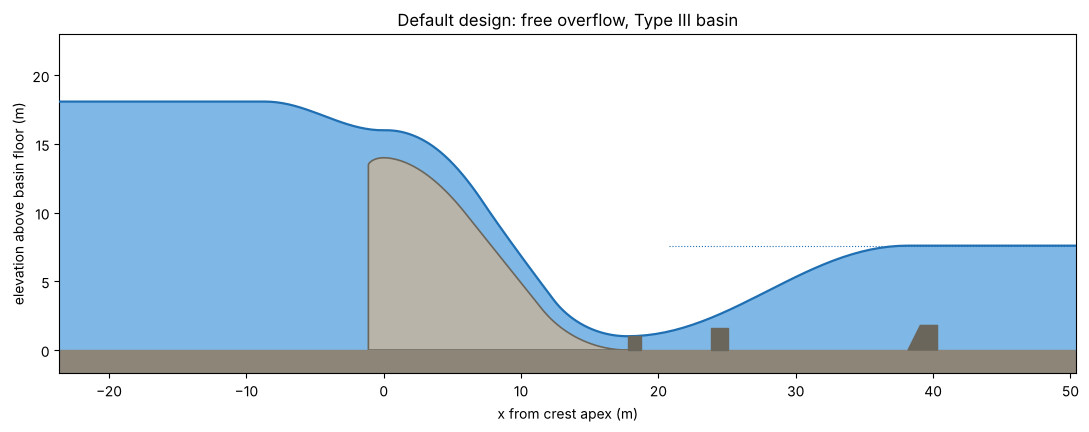

In [8]:
# 8. Profile drawn to scale: dam, crest, water surface, jump, basin ---------
def plot_profile(p, res, ax=None, title=None):
    sc = scene(p, res)
    if ax is None:
        fig, ax = plt.subplots(figsize=(11, 4.6))
    xl, xr, zt = sc["xl"], sc["xr"], sc["zTop"]
    # water: surface polyline above the bed
    bed_pts = sc["bed"]
    water = list(sc["surface"]) + [(xr, 0.0)] + [(res["geo"]["x_toe"], 0.0)] + bed_pts[::-1] + [(sc["x_up"], 0.0), (xl, 0.0)]
    ax.fill([a for a, b in water], [b for a, b in water], color="#7fb8e6", lw=0, zorder=1)
    ax.plot([a for a, b in sc["surface"]], [b for a, b in sc["surface"]], color="#1f6fb2", lw=1.6, zorder=3)
    ax.fill([a for a, b in sc["dam"]], [b for a, b in sc["dam"]], color="#b9b4aa", ec="#6b665c", lw=1.2, zorder=2)
    ax.fill_between([xl, xr], -0.12 * p["P"], 0, color="#8c8578", zorder=2)
    for poly in sc["baffles"]:
        ax.fill([a for a, b in poly], [b for a, b in poly], color="#6b665c", zorder=4)
    ax.axhline(sc["TW"], xmin=0.6, color="#1f6fb2", lw=0.8, ls=":", zorder=3)
    ax.set_xlim(xl, xr)
    ax.set_ylim(-0.12 * p["P"], zt)
    ax.set_aspect("equal")
    ax.set_xlabel("x from crest apex (m)")
    ax.set_ylabel("elevation above basin floor (m)")
    ax.set_title(title or "Spillway profile, to scale")
    return ax


fig, ax = plt.subplots(figsize=(11, 4.6))
plot_profile(p, res, ax, "Default design: free overflow, Type III basin")
plt.tight_layout()
plt.show()

Gate stops controlling (flow becomes free) at h = 0.109 m

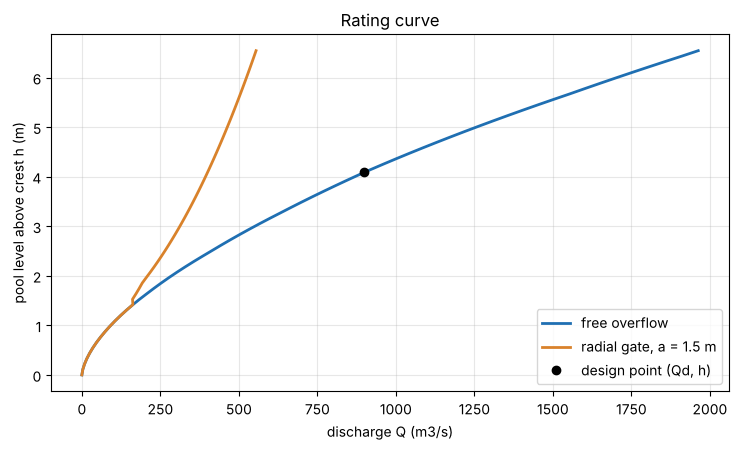

In [9]:
# 9. Rating curve: free overflow versus gated ---------------------------------
pg = dict(p, gate=True)
dsg = design_head(pg)
rt = rating(pg, dsg)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.plot(rt["free"], rt["h"], color="#1f6fb2", lw=2, label="free overflow")
ax.plot(rt["gate"], rt["h"], color="#d9822b", lw=2, label="radial gate, a = %.1f m" % pg["gateA"])
ax.plot([pg["Qd"]], [dsg["h_d"]], "ko", label="design point (Qd, h)")
ax.set_xlabel("discharge Q (m3/s)")
ax.set_ylabel("pool level above crest h (m)")
ax.set_title("Rating curve")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()
cross = next((h for h, f, g in zip(rt["h"], rt["free"], rt["gate"]) if g >= f - 1e-9 and h > 0), None)
print("Gate stops controlling (flow becomes free) at h = %s m" % (None if cross is None else round(cross, 3)))

In [10]:
# 10. Verification: independent checks -----------------------------------------
results = []
def check(name, ok, detail=""):
    results.append(ok)
    print(("PASS  " if ok else "FAIL  ") + name + ("   " + detail if detail else ""))

base = dict(p, gate=False)
rb = analyze(base)
Sb = summary(rb)

# 1. The design head reproduces the design flood.
dis = discharge(base, rb["ds"], rb["ds"]["h_d"])
check("Q(h_d) equals the design flood", abs(dis["Q"] - base["Qd"]) / base["Qd"] < 1e-6,
      "Q = %.4f vs Qd = %.4f" % (dis["Q"], base["Qd"]))

# 2. At He = Hd (hdRatio 1) the coefficient is C0 * f(P/Hd).
c_check = c_coeff(50.0, 5.0, 1.0)
check("C at He = Hd is 2.18 for a high dam", abs(c_check - 2.18) < 1e-12, "C = %.4f" % c_check)

# 3. Crest profile is C1-continuous: WES -> straight slope -> toe arc, and flat at the floor.
g_ = rb["geo"]
x, z = g_["x"], g_["z"]
i_t = int(np.argmin([abs(xi - g_["xt"]) for xi in x]))
sl_before = (z[i_t] - z[i_t - 1]) / (x[i_t] - x[i_t - 1])
sl_after = (z[i_t + 1] - z[i_t]) / (x[i_t + 1] - x[i_t])
check("slope continuous at the WES/straight tangent point", abs(sl_before - sl_after) < 0.01,
      "%.4f vs %.4f (target -%.4f)" % (sl_before, sl_after, 1 / base["slopeH"]))
sl_end = (z[-1] - z[-2]) / (x[-1] - x[-2])
check("bed is horizontal at the toe", abs(sl_end) < 0.05 and abs(z[-1]) < 1e-9, "end slope %.4f, z = %.1e" % (sl_end, z[-1]))
up = upstream_curve(rb["ds"]["Hd"])
check("upstream quadrant starts at the apex with zero drop", abs(up[-1][1]) < 1e-3 * rb["ds"]["Hd"], "drop = %.2e m" % up[-1][1])

# 4. Chute solver conserves energy when friction is switched off.
nf = dict(base, n=1e-9)
rnf = analyze(nf)
E_toe = rnf["y1"] + rnf["V1"] ** 2 / (2 * G)
check("frictionless chute: y1 + V1^2/2g = P + He", abs(E_toe - (nf["P"] + rnf["dis"]["He"])) < 1e-4,
      "%.5f vs %.5f" % (E_toe, nf["P"] + rnf["dis"]["He"]))
check("friction lowers toe velocity (and by a plausible amount)",
      rb["V1"] < rnf["V1"] and (rnf["V1"] - rb["V1"]) / rnf["V1"] < 0.12,
      "V1 %.2f vs %.2f m/s" % (rb["V1"], rnf["V1"]))

# 5. Bélanger sequent depth satisfies the momentum equation.
q, y1_, y2_ = rb["chute"]["q"], rb["y1"], rb["basin"]["y2"]
M1 = y1_ ** 2 / 2 + q * q / (G * y1_)
M2 = y2_ ** 2 / 2 + q * q / (G * y2_)
check("momentum balance across the jump", abs(M1 - M2) / M1 < 1e-9, "M1 = %.5f, M2 = %.5f" % (M1, M2))
check("jump energy loss equals E1 - E2", abs(rb["basin"]["dE_jump"] - ((y1_ + q * q / (2 * G * y1_ ** 2)) - (y2_ + q * q / (2 * G * y2_ ** 2)))) < 1e-8)

# 6. Rating curves.
rt0 = rating(base, rb["ds"])
check("free rating curve is strictly increasing", all(b > a for a, b in zip(rt0["free"], rt0["free"][1:])))
big = dict(base, gate=True, gateA=100.0)
check("a gate lifted clear of the water gives the free-overflow discharge",
      abs(discharge(big, rb["ds"], rb["ds"]["h_d"], big["gateA"])["Q"] - dis["Q"]) < 1e-9)
gq = discharge(dict(base, gate=True), rb["ds"], rb["ds"]["h_d"], 1.0)
check("a nearly closed gate controls and passes less than the free crest", gq["regime"] == "gate" and gq["Q"] < dis["Q"],
      "%.1f vs %.1f m3/s" % (gq["Q"], dis["Q"]))

# 7. Tailwater classification is consistent with y2.
for r_, want in ((0.80, "swept"), (1.0, "toe"), (1.4, "drowned")):
    chk = analyze(dict(base, TW=r_ * rb["basin"]["y2"]))
    check("TW = %.2f y2 -> %s" % (r_, want), chk["jump"]["state"] == want, "state = %s" % chk["jump"]["state"])

# 8. Swept-out jump: sequent depth of the local flow equals the tailwater at the jump position.
sw = analyze(dict(base, TW=0.92 * rb["basin"]["y2"]))
check("swept jump is found on the basin floor", sw["jump"]["x_jump"] is not None, "x_j = %s" % sw["jump"]["x_jump"])
yj = seq_depth(sw["jump"]["d_jump"], sw["jump"]["V_jump"])
check("swept jump: sequent depth at the jump equals TW", abs(yj - sw["p"]["TW"]) / sw["p"]["TW"] < 0.02,
      "y2(x_j) = %.3f, TW = %.3f, x_j = %.1f m" % (yj, sw["p"]["TW"], sw["jump"]["x_jump"]))
far = analyze(dict(base, TW=0.7 * rb["basin"]["y2"]))
check("a very low tailwater pushes the jump out of range (flagged SWEPT_FAR)", "SWEPT_FAR" in far["warnings"])

# 9. Drowned jump: sequent depth above the local bed equals the tailwater at the jump toe.
dr = analyze(dict(base, TW=1.4 * rb["basin"]["y2"]))
jd = dr["jump"]
check("drowned jump: y2(local) + bed elevation = TW", abs(seq_depth(jd["d_jump"], jd["V_jump"]) + jd["z_jump"] - dr["p"]["TW"]) < 0.05,
      "toe at x = %.2f m, bed z = %.2f m" % (jd["x_jump"], jd["z_jump"]))

print("\n%d of %d checks passed" % (sum(results), len(results)))
assert all(results), "a check failed"

PASS  Q(h_d) equals the design flood   Q = 900.0000 vs Qd = 900.0000
PASS  C at He = Hd is 2.18 for a high dam   C = 2.1800
PASS  slope continuous at the WES/straight tangent point   -1.2487 vs -1.2500 (target -1.2500)
PASS  bed is horizontal at the toe   end slope -0.0112, z = 0.0e+00
PASS  upstream quadrant starts at the apex with zero drop   drop = -5.37e-04 m
PASS  frictionless chute: y1 + V1^2/2g = P + He   18.14021 vs 18.14021
PASS  friction lowers toe velocity (and by a plausible amount)   V1 17.90 vs 18.35 m/s
PASS  momentum balance across the jump   M1 = 33.34546, M2 = 33.34546
PASS  jump energy loss equals E1 - E2
PASS  free rating curve is strictly increasing
PASS  a gate lifted clear of the water gives the free-overflow discharge
PASS  a nearly closed gate controls and passes less than the free crest   289.3 vs 900.0 m3/s
PASS  TW = 0.80 y2 -> swept   state = swept
PASS  TW = 1.00 y2 -> toe   state = toe
PASS  TW = 1.40 y2 -> drowned   state = drowned
PASS  swept jump is fo

scenario                                 Q m3/s    y1 m  V1 m/s    Fr1    y2 m  jump     L basin
Free overflow, Type III basin             900.0   1.006   17.90   5.70   7.617  toe      20.4 m
Radial gate, a = 1.5 m                    400.4   0.460   17.39   8.18   5.103  drowned  12.7 m
Plain basin (no baffles)                  900.0   1.006   17.90   5.70   7.617  toe      45.7 m
Tailwater too low: jump swept downstream    900.0   1.006   17.90   5.70   7.617  swept    20.4 m
Tailwater too high: jump drowned          900.0   1.006   17.90   5.70   7.617  drowned  20.4 m

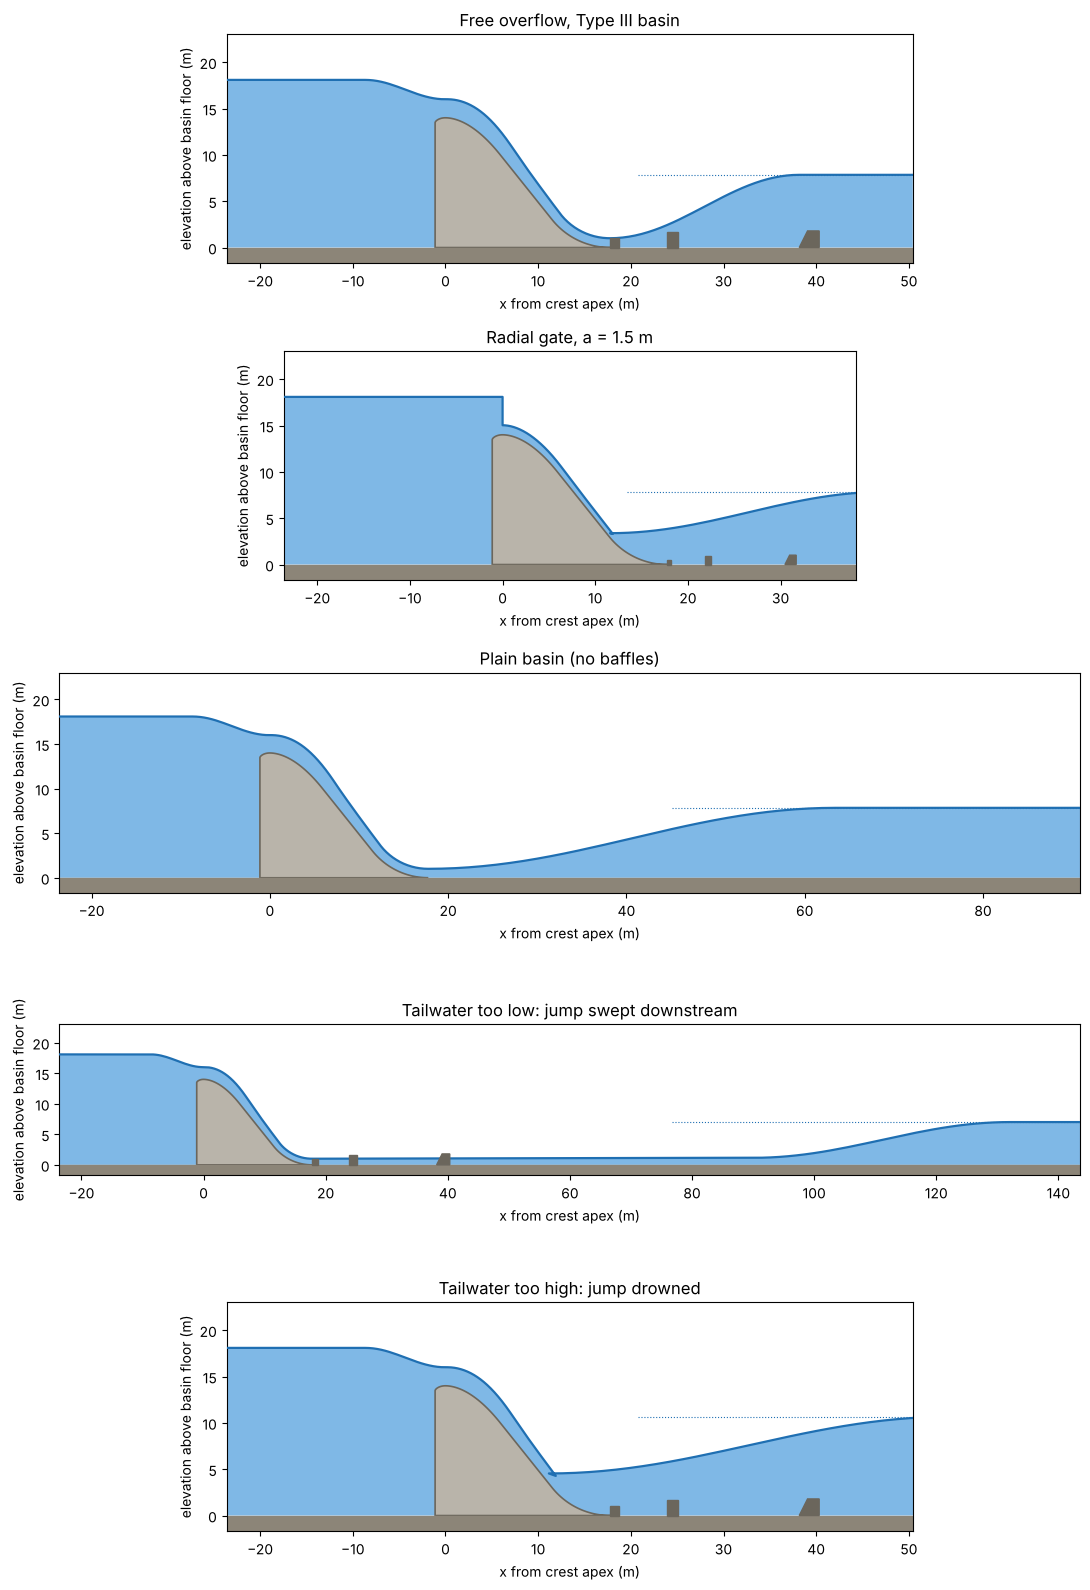

In [11]:
# 11. Scenario comparison: the five stories the app can tell -------------------
y2_ref = analyze(dict(p, gate=False))["basin"]["y2"]
SCENARIOS = [
    ("Free overflow, Type III basin",           dict(p, gate=False, TW=1.03 * y2_ref), None),
    ("Radial gate, a = 1.5 m",                  dict(p, gate=True, gateA=1.5, TW=1.03 * y2_ref), None),
    ("Plain basin (no baffles)",                dict(p, gate=False, basin="plain", TW=1.03 * y2_ref), None),
    ("Tailwater too low: jump swept downstream",dict(p, gate=False, TW=0.92 * y2_ref), None),
    ("Tailwater too high: jump drowned",        dict(p, gate=False, TW=1.40 * y2_ref), None),
]
print("%-38s %8s %7s %7s %6s %7s  %-8s %s" % ("scenario", "Q m3/s", "y1 m", "V1 m/s", "Fr1", "y2 m", "jump", "L basin"))
for name, pp, hop in SCENARIOS:
    r_ = analyze(pp, hop)
    s_ = summary(r_)
    print("%-38s %8.1f %7.3f %7.2f %6.2f %7.3f  %-8s %.1f m" % (name, s_["Q"], s_["y1"], s_["V1"], s_["Fr1"], s_["y2"], s_["state"], s_["L_basin"]))

fig, axes = plt.subplots(len(SCENARIOS), 1, figsize=(11, 3.2 * len(SCENARIOS)))
for ax, (name, pp, hop) in zip(axes, SCENARIOS):
    plot_profile(pp, analyze(pp, hop), ax, name)
plt.tight_layout()
plt.show()

In [12]:
# 12. Export: test cases for the JavaScript engine, plus CSVs -------------------
def pick(seq, idx):
    return [seq[i] for i in idx]

def cleaned(o):
    """Make a structure JSON-safe (tuples -> lists, numpy -> python)."""
    if isinstance(o, dict):
        return {k: cleaned(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [cleaned(v) for v in o]
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    return o

y2d = analyze(dict(p, gate=False))["basin"]["y2"]
CASES = [
    ("default free, type III",   dict(p, gate=False, TW=1.03 * y2d), None),
    ("default, operating at 60% of design head", dict(p, gate=False, TW=1.03 * y2d), 0.6),
    ("default, operating at 130% of design head", dict(p, gate=False, TW=1.03 * y2d), 1.3),
    ("gated a=1.5",              dict(p, gate=True, gateA=1.5, TW=1.03 * y2d), None),
    ("gated a=0.6 at 120%",      dict(p, gate=True, gateA=0.6, TW=1.03 * y2d), 1.2),
    ("plain basin",              dict(p, gate=False, basin="plain", TW=1.03 * y2d), None),
    ("swept out (jump on the floor)", dict(p, gate=False, TW=0.92 * y2d), None),
    ("swept far (out of range)", dict(p, gate=False, TW=0.70 * y2d), None),
    ("drowned",                  dict(p, gate=False, TW=1.40 * y2d), None),
    ("hdRatio 0.8, no piers",    dict(p, gate=False, hdRatio=0.8, N=0, TW=1.03 * y2d), 1.0),
    ("tall dam, big flood",      dict(p, gate=False, Qd=3000.0, L=80.0, N=3, P=45.0, R=15.0, slopeH=0.75, TW=22.0), None),
    ("low dam (geometry limit)", dict(p, gate=False, Qd=1500.0, P=6.0, TW=4.0), None),
]
cases_out = []
for name, pp, frac in CASES:
    ds_ = design_head(pp)
    h_op = None if frac is None else frac * ds_["h_d"]
    r_ = analyze(pp, h_op)
    sc_ = scene(pp, r_)
    rt_ = rating(pp, r_["ds"], 60)
    idx = list(range(0, 61, 6))
    surf = sc_["surface"]
    cases_out.append(cleaned(dict(
        name=name, params=pp, h_op=h_op, expected=summary(r_),
        rating=dict(h=pick(rt_["h"], idx), free=pick(rt_["free"], idx),
                    gate=None if rt_["gate"] is None else pick(rt_["gate"], idx)),
        scene=dict(n_surface=len(surf), n_dam=len(sc_["dam"]), n_baffles=len(sc_["baffles"]),
                   surface_first=surf[0], surface_last=surf[-1], surface_mid=surf[len(surf) // 2],
                   dam_mid=sc_["dam"][len(sc_["dam"]) // 2], xl=sc_["xl"], xr=sc_["xr"], zTop=sc_["zTop"]),
        chute_samples=None if r_["no_flow"] else dict(
            idx=[0, len(r_["chute"]["d"]) // 4, len(r_["chute"]["d"]) // 2, 3 * len(r_["chute"]["d"]) // 4, len(r_["chute"]["d"]) - 1],
            d=pick(r_["chute"]["d"], [0, len(r_["chute"]["d"]) // 4, len(r_["chute"]["d"]) // 2, 3 * len(r_["chute"]["d"]) // 4, len(r_["chute"]["d"]) - 1]),
            V=pick(r_["chute"]["V"], [0, len(r_["chute"]["d"]) // 4, len(r_["chute"]["d"]) // 2, 3 * len(r_["chute"]["d"]) // 4, len(r_["chute"]["d"]) - 1])),
    )))

with open(OUT / "test_cases.json", "w") as f:
    json.dump(dict(generated_by="spillway_design.ipynb", tolerance_rel=1e-6, cases=cases_out), f, indent=1, allow_nan=False)

# CSV of the default crest profile and rating curve
rd = analyze(dict(p, gate=False, TW=1.03 * y2d))
sc_ = scene(rd["p"], rd)
with open(OUT / "profile.csv", "w") as f:
    f.write("x_m,elevation_above_floor_m\n")
    for x_, z_ in sc_["bed"]:
        f.write("%.4f,%.4f\n" % (x_, z_))
rtd = rating(dict(p, gate=True), design_head(dict(p, gate=True)), 60)
with open(OUT / "rating_curve.csv", "w") as f:
    f.write("h_m,Q_free_m3s,Q_gate_m3s\n")
    for h_, a_, b_ in zip(rtd["h"], rtd["free"], rtd["gate"]):
        f.write("%.4f,%.3f,%.3f\n" % (h_, a_, b_))
print("wrote", len(cases_out), "test cases +", ", ".join(sorted(x.name for x in OUT.iterdir())))

wrote 12 test cases + profile.csv, rating_curve.csv, test_cases.json

## Assumptions and limits (read before trusting a number)

**What this models well:** the head–discharge relation of a high WES ogee crest with a vertical upstream face, the real crest shape, a friction-corrected water surface down the chute, and the hydraulic jump relations.

**Simplifications, all deliberate:**

- `CR_TABLE` (C/Cd versus He/Hd) and `TYPE3_L_TABLE` (basin length) are approximate readings of published charts. The low-dam factor $f(P/H_d)$ is a rough interpolation to a broad-crested value. Replace them with your agency's charts for final design.
- Approach width is taken equal to the crest length; the approach velocity head is small for high dams.
- Chute flow is one-dimensional. Along the WES curve the pressure coefficient $\beta$ runs from $\max(0, 1 - H_e/H_d)$ at the apex (a free-fall nappe when the crest runs at its design head) to 1 at the tangent point, and stays hydrostatic on the slope and toe arc. This is a smooth engineering device, not a pressure measurement. With a gate, $\beta = 1$ throughout. There is **no air entrainment (bulking)** and no boundary-layer development, so depths on a long chute are slightly under-predicted. Above about 30 m/s the app warns about cavitation and aeration.
- The toe arc is treated hydrostatically (no centrifugal pressure term).
- The jump position for swept-out and drowned cases comes from a sequent-depth match, not a full momentum analysis with the slope term.
- The gate is a radial gate seated on the crest; $C_d$ falls from 0.75 with opening ratio $a/H_e$ (clamped 0.55 to 0.75). Real $C_d$ depends on the lip geometry and trunnion height.
- Type III proportions: chute blocks $h = w = s = y_1$; baffle blocks $h_3 = y_1(4+Fr_1)/6$, $w = s = 0.75h_3$, placed $0.8y_2$ downstream of the chute blocks; end sill $h_4 = y_1(5+Fr_1)/6$. USBR limits Type III to $Fr_1 > 4.5$ and $V_1 \le 18$ m/s, and the app warns when you leave that range.
- Tailwater is an input, not a computed rating curve of the river.

**Not covered:** stepped chutes, side-channel or labyrinth crests, upstream faces other than vertical, submergence of the crest by tailwater, scour, structural stability, sediment, and energy dissipators other than the two basins above.

This is a teaching and preliminary-design tool. It does not replace a design review by a qualified dam engineer.